# O-level Mathematics Score Prediction: Analysis Report

**Goal:** predict each student's O-level mathematics score so the school can identify weaker students and offer
support **before** the examination.

This notebook is the analysis and reporting layer. The pipeline itself (validation, cleaning, features, models,
evaluation) lives in the tested `src/` package and is run with `python main.py train`, which writes a versioned run
to `artifacts/<run_id>/`. This notebook:

1. states and **verifies every assumption** about the data (the brief warns that some features may be synthetic);
2. explores what drives the scores;
3. reads the saved run artifacts to compare the models and explain the recommendation.

*Run All* works straight after cloning (it uses the committed summary in `reports/latest_run/`); after
`python main.py train` it reports on your own latest run.

## 1. Setup

In [1]:
import json
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from scipy import stats

from src.artifacts import latest_run_dir
from src.config import load_config
from src.data import clean, load_raw
from src.features import add_features
from src.schema import validate_raw

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

cfg = load_config("configs/config.yaml")
try:
    RUN = latest_run_dir(cfg["artifacts"]["dir"])
except FileNotFoundError:
    RUN = Path(cfg["artifacts"]["report_dir"])
card = json.loads((RUN / "model_card.json").read_text())
metric = lambda name, **kw: pd.read_csv(RUN / "metrics" / f"{name}.csv", **kw)
NAMES = {"linear_regression": "Linear (Ridge)", "random_forest": "Random Forest",
         "gradient_boosting": "Gradient Boosting"}
WEAK = cfg["weak_students"]["score_threshold"]
raw = load_raw(cfg["data"]["path"])
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns | reporting on run {card['run_id']} from {RUN}")
raw.head()

Raw data: 15,900 rows x 18 columns | reporting on run final from reports/latest_run


,index,number_of_siblings,direct_admission,CCA,learning_style,student_id,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
0,0,0,Yes,Sports,Visual,ACN2BE,Female,No,69.0,14.0,2.0,16.0,10.0,91.0,22:00,6:00,private transport,yellow
1,1,2,No,Sports,Auditory,FGXIIZ,Female,No,47.0,4.0,19.0,16.0,7.0,94.0,22:30,6:30,private transport,green
2,2,0,Yes,NaN,Visual,B9AI9F,Male,No,85.0,14.0,2.0,15.0,8.0,92.0,22:30,6:30,private transport,white
3,3,1,No,Clubs,Auditory,FEVM1T,Female,Yes,64.0,2.0,20.0,15.0,18.0,NaN,21:00,5:00,public transport,yellow
4,4,0,No,Sports,Auditory,AXZN2E,Male,No,66.0,24.0,3.0,16.0,7.0,95.0,21:30,5:30,public transport,yellow


## 2. Data quality: what the schema check finds

In [2]:
rep = validate_raw(raw)
print("Fatal errors:", rep.errors or "none")
pd.Series(rep.warnings, name="rows affected").to_frame()

Fatal errors: none


,rows affected
duplicate_student_records (merged),900
final_test_missing (rows dropped),495
CCA_missing (means no CCA),3829
CCA_inconsistent_case,509
tuition_abbreviated (Y/N),588
age_out_of_range,451
attendance_rate_missing,778


## 3. Assumptions and their verification

The attribute tables were not part of the brief, so each column's meaning is inferred from the data. Every
assumption below is **tested** rather than taken for granted.

### A1. Repeated `student_id`s are the same student recorded twice

In [3]:
dups = raw[raw.student_id.duplicated(keep=False)]
g = dups.groupby("student_id")
cols = [c for c in raw.columns if c not in ["index", "student_id"]]
differs = {c: int((g[c].nunique(dropna=True) > 1).sum()) for c in cols}
print(f"{raw.student_id.duplicated().sum()} duplicate records, all in pairs: {g.size().value_counts().to_dict()}")
pd.Series(differs, name="pairs whose non-missing values differ").to_frame().T

900 duplicate records, all in pairs: {2: 900}


,number_of_siblings,direct_admission,CCA,learning_style,gender,tuition,final_test,n_male,n_female,age,hours_per_week,attendance_rate,sleep_time,wake_time,mode_of_transport,bag_color
pairs whose non-missing values differ,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,729


In [4]:
miss = {c: int((g[c].apply(lambda s: s.isna().any() and s.notna().any())).sum()) for c in ["final_test", "attendance_rate"]}
print("Pairs where one copy is missing a value the other has:", miss)

Pairs where one copy is missing a value the other has: {'final_test': 52, 'attendance_rate': 90}


**Verified.** The 900 duplicated IDs come in pairs that agree on **every** attribute except `bag_color` (and `index`).
Where they seem to differ in `final_test` or `attendance_rate`, one copy is simply missing the value. Merging each
pair and keeping the first non-missing value loses nothing (`src/data.merge_duplicates`, which also logs any
genuine conflict; there are none).

### A2. `bag_color` is a synthetic, meaningless feature

In [5]:
print(f"Bag colour differs within {differs['bag_color']} of 900 duplicate pairs (same student, different colour)")
groups = [s.dropna() for _, s in raw.groupby("bag_color").final_test]
print("ANOVA of score by bag colour: p = %.3f" % stats.f_oneway(*groups).pvalue)
raw.groupby("bag_color").final_test.agg(["mean", "std", "count"]).round(2)

Bag colour differs within 729 of 900 duplicate pairs (same student, different colour)
ANOVA of score by bag colour: p = 0.238


,mean,std,count
bag_color,,,
black,67.36,13.87,2570
blue,67.11,13.83,2550
green,66.56,14.13,2555
red,67.43,13.96,2541
white,67.14,13.91,2531
yellow,67.37,14.14,2658


**Verified.** The same student has a different bag colour in 81% of duplicate pairs, so the value is randomly
generated, and score does not differ by colour (ANOVA p > 0.05). `bag_color` is **excluded** from modelling (listed
under `features.excluded` in the config with the reason).

### A3. Other candidate synthetic features

In [6]:
df = add_features(clean(raw)[0])
tests = []
for c in ["gender", "mode_of_transport", "wake_time", "learning_style", "direct_admission", "tuition", "CCA"]:
    groups = [s for _, s in df.groupby(c).final_test]
    tests.append({"feature": c, "test": "ANOVA", "p_value": stats.f_oneway(*groups).pvalue,
                  "effect (max - min group mean)": df.groupby(c).final_test.mean().agg(np.ptp)})
for c in ["age", "number_of_siblings", "hours_per_week", "attendance_rate", "class_size", "male_ratio", "sleep_hours"]:
    s = df[[c, "final_test"]].dropna()
    tests.append({"feature": c, "test": "Spearman", "p_value": stats.spearmanr(s[c], s.final_test).pvalue,
                  "effect (max - min group mean)": np.nan, "rho": stats.spearmanr(s[c], s.final_test).statistic})
pd.DataFrame(tests).set_index("feature").round(4)

,test,p_value,effect (max - min group mean),rho
feature,,,,
gender,ANOVA,0.1775,0.3124,NaN
mode_of_transport,ANOVA,0.8390,0.1529,NaN
wake_time,ANOVA,0.9078,0.3602,NaN
learning_style,ANOVA,0.0000,7.6903,NaN
direct_admission,ANOVA,0.0000,7.4940,NaN
tuition,ANOVA,0.0000,7.5967,NaN
CCA,ANOVA,0.0000,12.8353,NaN
age,Spearman,0.8227,NaN,0.0019
number_of_siblings,Spearman,0.0000,NaN,-0.3668


`gender`, `mode_of_transport`, `wake_time` and `age` show **no** relationship with the score (p > 0.05, group means
within ~0.5 marks). Unlike `bag_color`, they are plausible real attributes and are consistent within duplicate
records, so they are **kept**: the tree models simply ignore them, and the permutation-importance results in
Section 7 confirm they contribute nothing. `wake_time` is still used, combined with `sleep_time`, to compute
`sleep_hours`.

### A4. Missing `CCA` means the student has no CCA

In [7]:
cca = raw.CCA.str.title()
none_scores, missing_scores = raw.final_test[cca == "None"].dropna(), raw.final_test[cca.isna()].dropna()
print(f"Mean score: CCA 'None' = {none_scores.mean():.2f} | CCA missing = {missing_scores.mean():.2f} | "
      f"any CCA = {raw.final_test[cca.isin(['Sports', 'Clubs', 'Arts'])].mean():.2f}")
print("Kolmogorov-Smirnov test, 'None' vs missing: p = %.3f" % stats.ks_2samp(none_scores, missing_scores).pvalue)

Mean score: CCA 'None' = 76.67 | CCA missing = 76.78 | any CCA = 63.98
Kolmogorov-Smirnov test, 'None' vs missing: p = 0.637


**Verified.** Students with a missing CCA score exactly like those recorded as "None" (same distribution, KS test
p > 0.05) and very differently from students with a CCA. Missing is therefore recoded to "None", rather than imputed
with the most frequent CCA, which would be wrong.

### A5. Ages 5 and 6 are typing errors for 15 and 16; negative ages are invalid

In [8]:
display(raw.groupby("age").final_test.agg(["mean", "count"]).round(2))
print("KS test, age 5 vs 15: p = %.3f | age 6 vs 16: p = %.3f" % (
    stats.ks_2samp(raw.final_test[raw.age == 5].dropna(), raw.final_test[raw.age == 15].dropna()).pvalue,
    stats.ks_2samp(raw.final_test[raw.age == 6].dropna(), raw.final_test[raw.age == 16].dropna()).pvalue))

,mean,count
age,,
-5.0,69.50,4
-4.0,48.00,1
5.0,66.45,206
6.0,65.65,225
15.0,67.11,7483
16.0,67.28,7486


KS test, age 5 vs 15: p = 0.767 | age 6 vs 16: p = 0.139


**Verified.** Secondary-school students sitting the O-level are 15–16. The 446 records with age "5" or "6" have the same
score distribution as 15/16-year-olds, consistent with a dropped leading "1". They are corrected (+10). The 5
negative ages cannot be repaired and are set to missing (then imputed).

### A6. `Y`/`N` in `tuition` mean Yes/No; CCA capitals are the same categories

In [9]:
display(raw.groupby("tuition").final_test.mean().round(2).to_frame("mean score"))
display(raw.groupby(raw.CCA.fillna("(missing)")).final_test.mean().round(2).to_frame("mean score"))

,mean score
tuition,
N,61.71
No,62.91
Y,72.01
Yes,70.41


,mean score
CCA,
(missing),76.78
ARTS,64.12
Arts,64.06
CLUBS,61.19
Clubs,63.95
NONE,76.67
SPORTS,63.50
Sports,64.06


**Verified.** `Y` scores like `Yes` and `N` like `No`; `CLUBS` like `Clubs`, etc. They are standardised.

### A7. Sleep times after midnight belong to the next day

In [10]:
display(pd.crosstab(raw.sleep_time, raw.wake_time))
display(df.groupby("sleep_hours").final_test.agg(["mean", "count"]).round(2))

wake_time,5:00,5:30,6:00,6:30,7:00
sleep_time,,,,,
0:00,67,0,46,0,127
0:30,0,38,0,55,0
1:00,40,0,38,0,44
1:30,0,29,0,44,0
21:00,2953,0,0,0,0
21:30,0,2875,0,0,0
22:00,146,0,2921,0,0
22:30,0,128,0,2906,0
23:00,40,0,125,0,2966


,mean,count
sleep_hours,,
4.0,43.83,136
5.0,45.07,214
6.0,45.64,218
7.0,61.58,598
8.0,68.38,13393


**Verified.** Bedtimes run from 21:00 to 03:00 and wake times from 05:00 to 07:00. Treating 00:00–03:00 as after
midnight gives sleep durations of 4–8 hours; most students sleep exactly 8. Two features are derived:
`sleep_hours` and `sleep_after_midnight`. Students who sleep after midnight score about 20 marks lower.

### A8. Missing `final_test` rows cannot be used; missing `attendance_rate` is not informative

In [11]:
print(f"Missing target after merging duplicates: {clean(raw, require_target=False)[0].final_test.isna().sum()} students (dropped)")
att_missing = raw.attendance_rate.isna()
print(f"Mean score with attendance missing: {raw.final_test[att_missing].mean():.2f} vs present: "
      f"{raw.final_test[~att_missing].mean():.2f}")

Missing target after merging duplicates: 441 students (dropped)
Mean score with attendance missing: 67.54 vs present: 67.15


**Verified.** Students without a score cannot be used for training (they could be scored by the model later).
Attendance is missing for ~5% of records, and those students score the same on average as everyone else, so median
imputation with a missing-value indicator is appropriate.

### A9. `n_male` / `n_female` describe the student's class

In [12]:
g = df.groupby(pd.cut(df.class_size, [0, 15, 20, 25, 30, 70])).final_test.agg(["mean", "count"]).round(2)
g

,mean,count
class_size,,
"(0, 15]",75.74,492
"(15, 20]",74.28,3920
"(20, 25]",67.67,6111
"(25, 30]",58.66,3823
"(30, 70]",56.18,213


**Assumed and supported.** The counts vary per student, range from 0 to 31 per gender and total 14–31, a plausible
class size. Larger classes score markedly lower, a sensible relationship, so `class_size` and
`male_ratio` are derived.

### Summary of cleaning (from the run's data report)

In [13]:
data_report = json.loads((RUN / "data_report.json").read_text())
pd.Series({k: v for k, v in data_report["cleaning"].items() if not isinstance(v, dict)}, name="rows").to_frame()

,rows
rows_in,15900
duplicate_records_merged,900
dropped_missing_target,441
CCA_missing_set_to_None,3499
CCA_recased,471
tuition_expanded,532
age_typo_fixed (+10),415
age_invalid_set_missing,5
rows_out,14559


## 4. What drives the score

14,559 students | mean score 67.2 | 12.0% below 50 (weak)


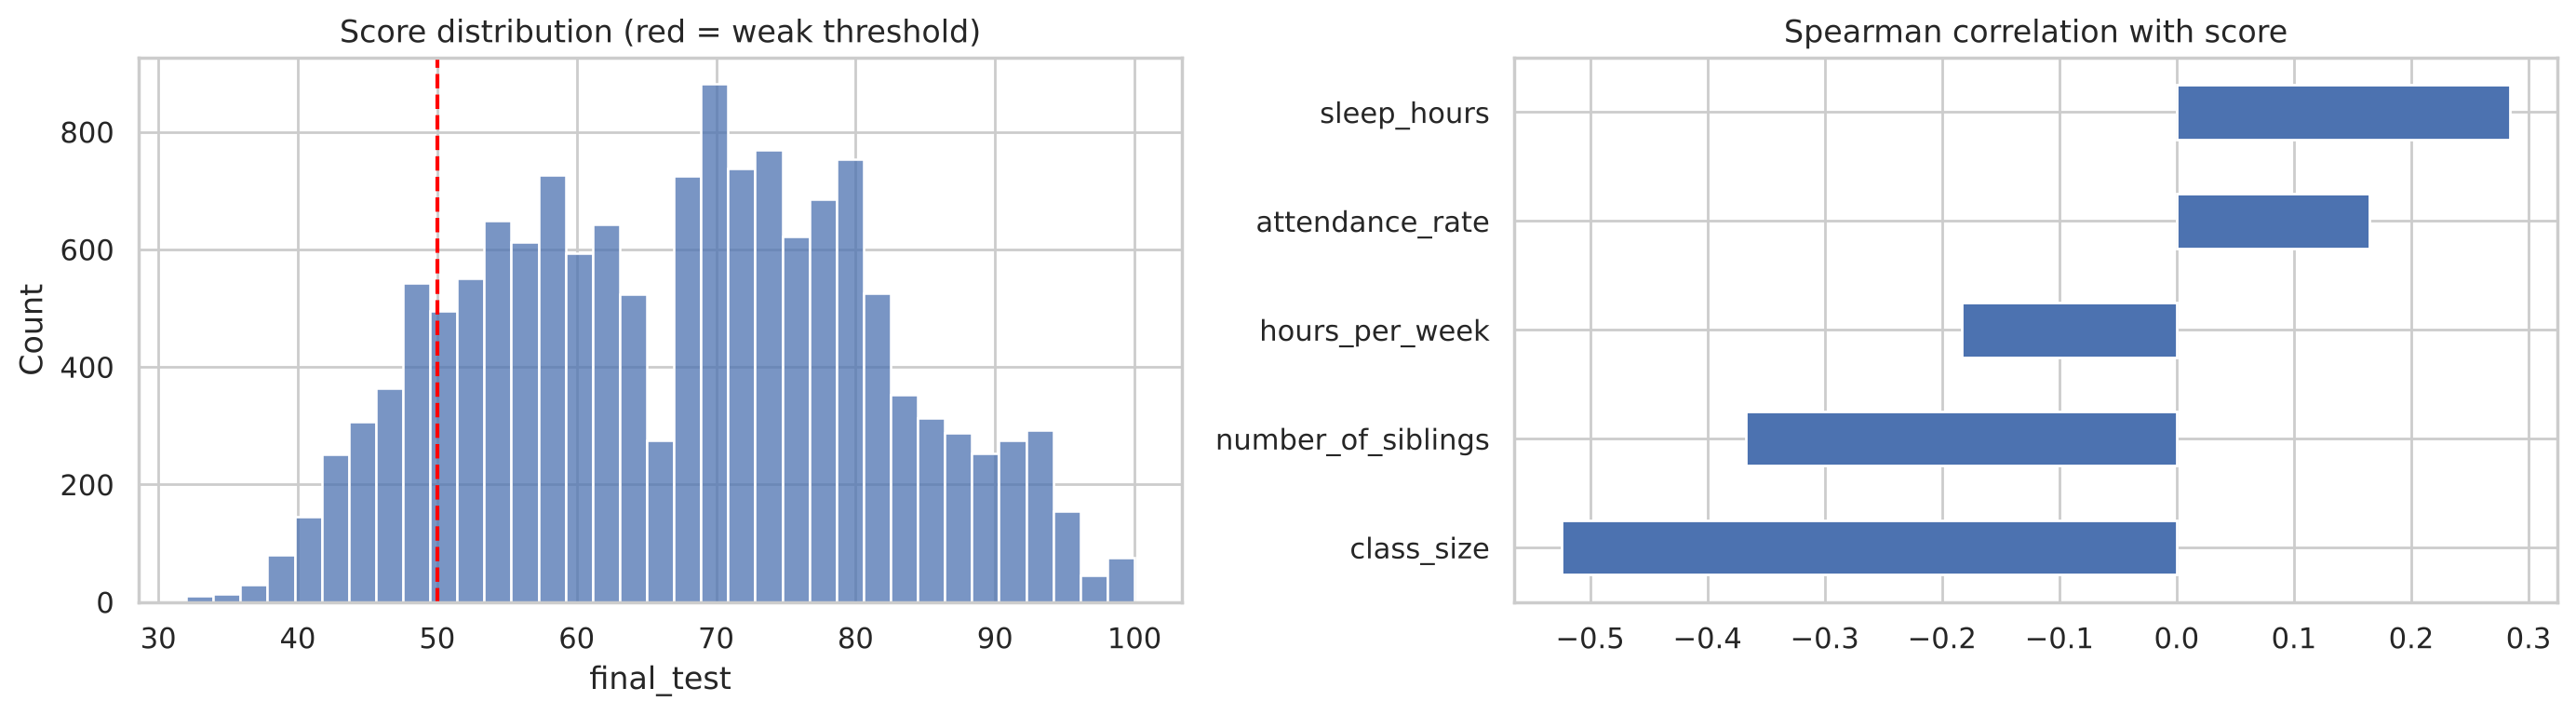

In [14]:
rate = (df.final_test < WEAK).mean()
print(f"{len(df):,} students | mean score {df.final_test.mean():.1f} | {rate:.1%} below {WEAK} (weak)")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df.final_test, bins=35, ax=axes[0]); axes[0].axvline(WEAK, color="red", ls="--")
axes[0].set_title("Score distribution (red = weak threshold)")
num = ["hours_per_week", "attendance_rate", "class_size", "sleep_hours", "number_of_siblings"]
corr = df[num + ["final_test"]].corr(method="spearman")["final_test"].drop("final_test").sort_values()
corr.plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("Spearman correlation with score")
plt.tight_layout(); plt.show()

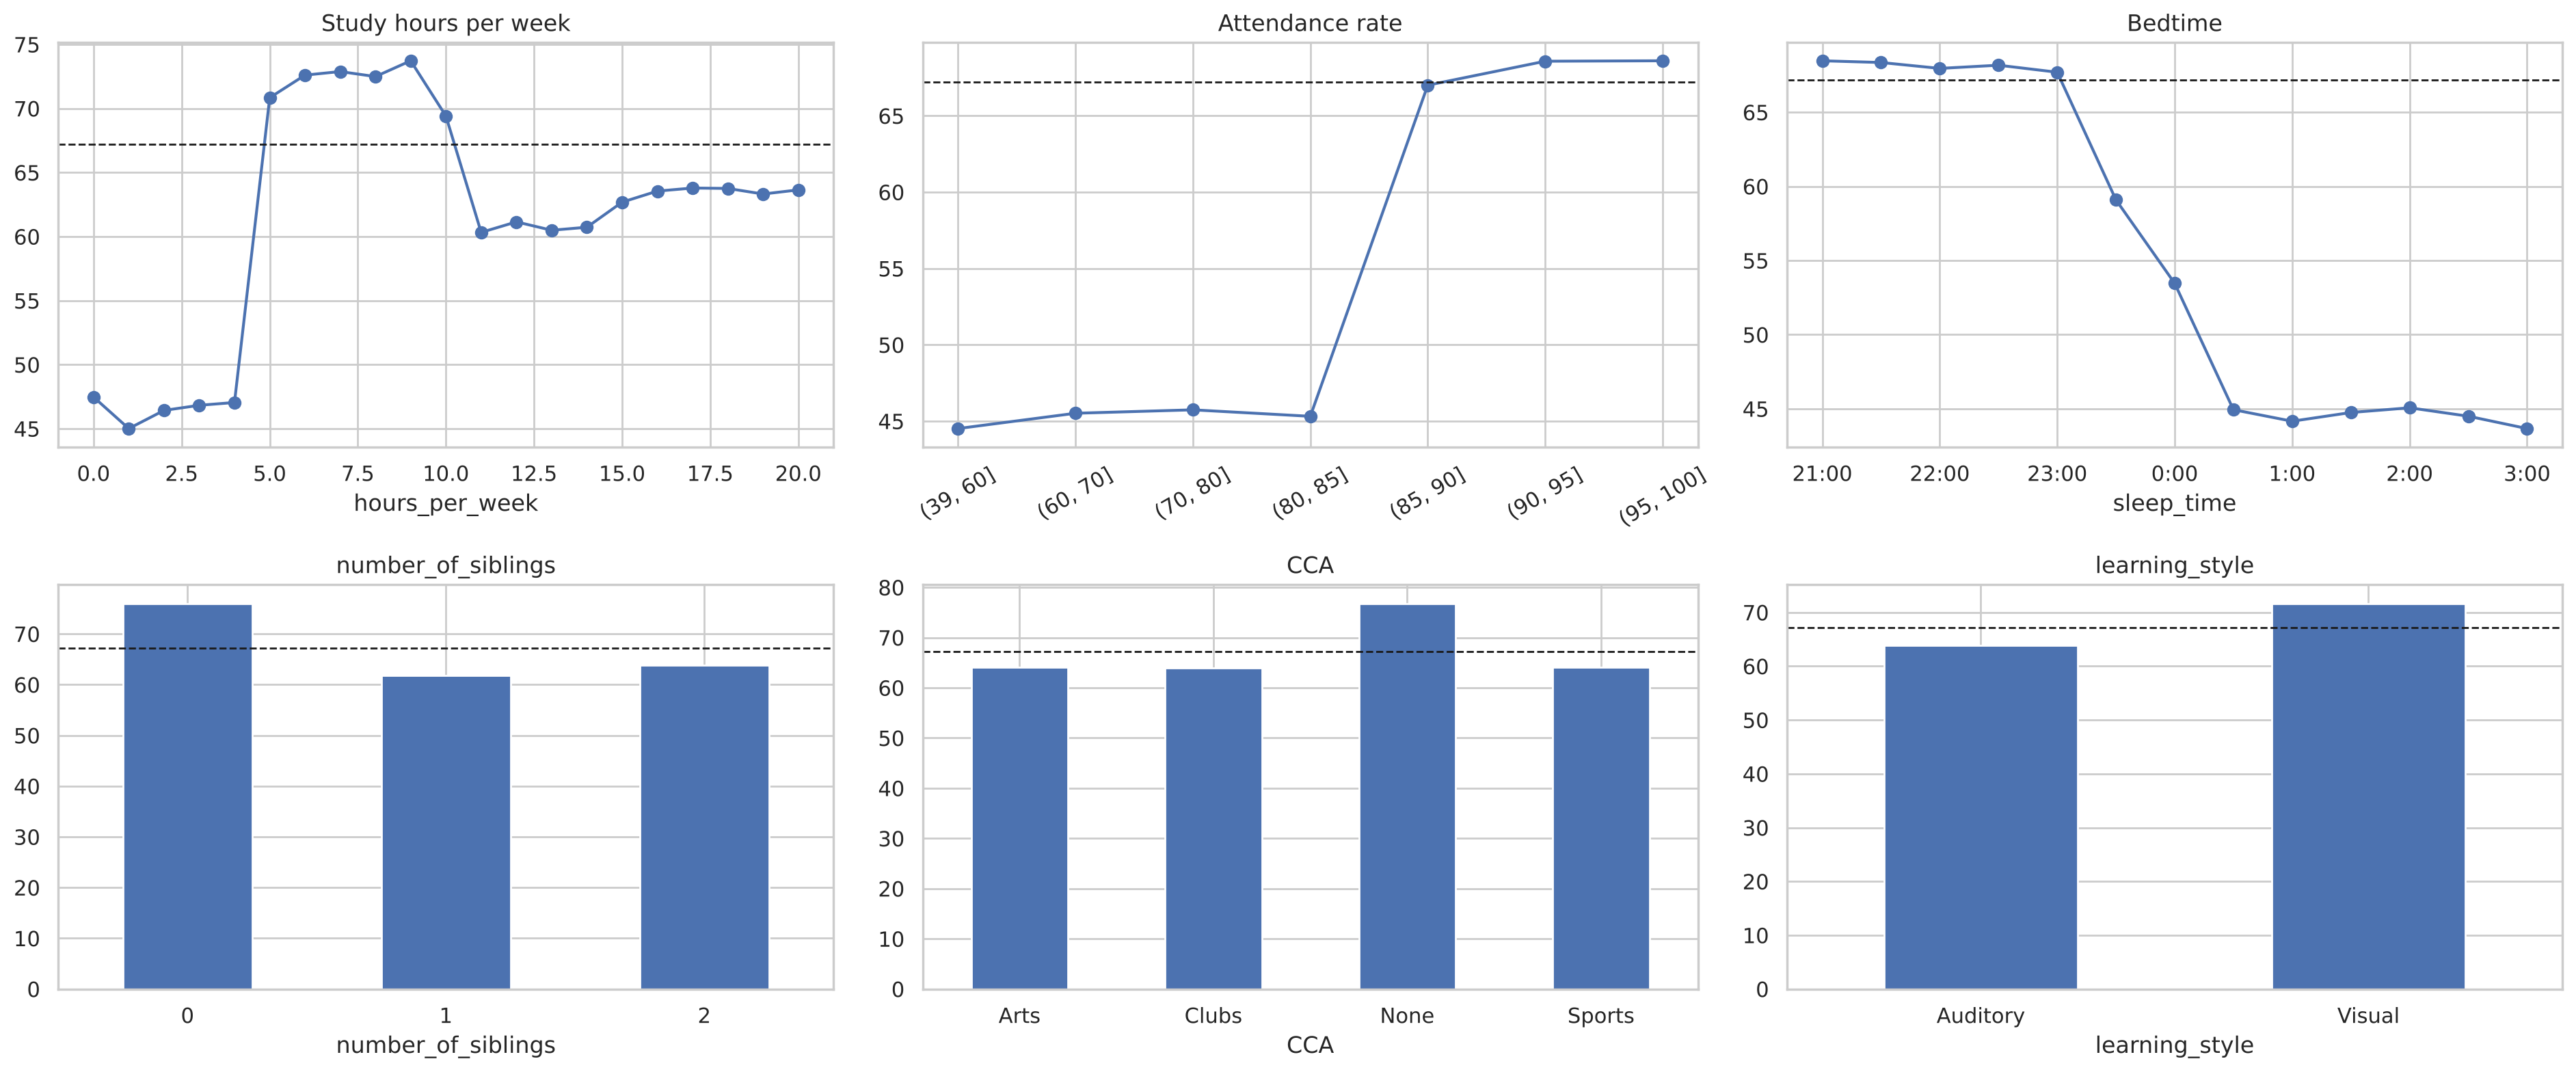

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(19, 8))
df.groupby("hours_per_week").final_test.mean().plot(ax=axes[0, 0], marker="o", title="Study hours per week")
att = df.groupby(pd.cut(df.attendance_rate, [39, 60, 70, 80, 85, 90, 95, 100])).final_test.mean()
axes[0, 1].plot(range(len(att)), att.values, "o-"); axes[0, 1].set_xticks(range(len(att)), [str(i) for i in att.index], rotation=30)
axes[0, 1].set_title("Attendance rate")
df.groupby("sleep_time").final_test.mean().reindex(
    ["21:00", "21:30", "22:00", "22:30", "23:00", "23:30", "0:00", "0:30", "1:00", "1:30", "2:00", "2:30", "3:00"]
).plot(ax=axes[0, 2], marker="o", title="Bedtime")
for ax, c in zip(axes[1], ["number_of_siblings", "CCA", "learning_style"]):
    df.groupby(c).final_test.mean().plot.bar(ax=ax, color="#4C72B0", title=c, rot=0)
for ax in axes.ravel():
    ax.axhline(df.final_test.mean(), color="k", ls="--", lw=1)
plt.tight_layout(); plt.show()

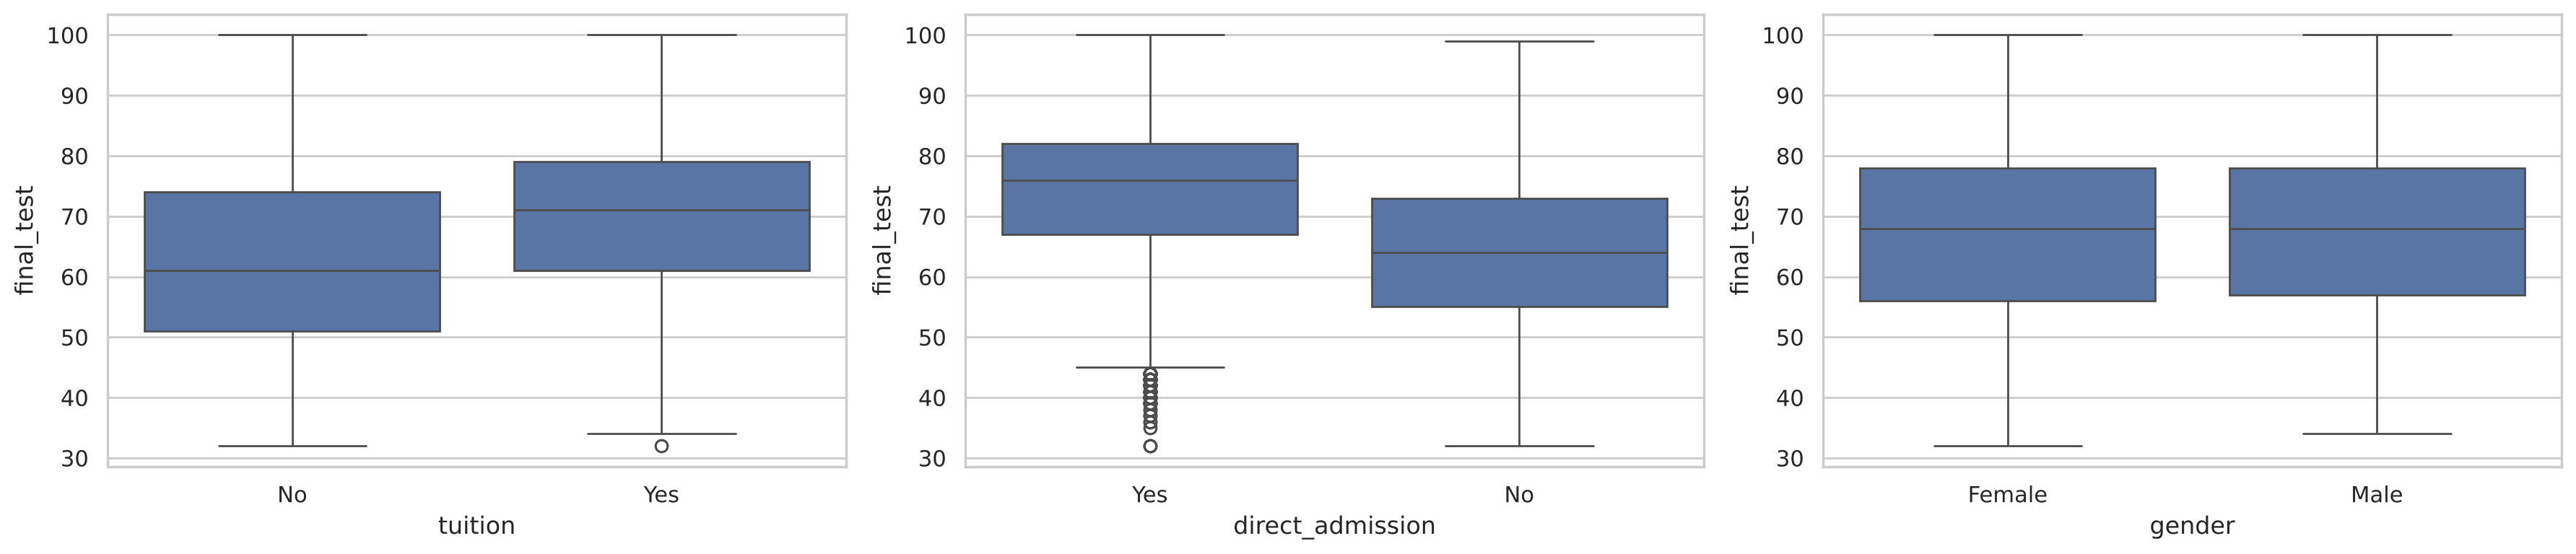

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ["tuition", "direct_admission", "gender"]):
    sns.boxplot(data=df, x=c, y="final_test", ax=ax)
plt.tight_layout(); plt.show()

**Key drivers**

1. **Study hours have a step-shaped effect:** 0–4 hours ≈ 46, 5–9 hours ≈ 72, 11+ hours ≈ 61 (studying a lot is
   linked with lower scores, possibly struggling students working harder).
2. **Attendance below 80% is a cliff:** about 45 marks vs 64–69 above 80%.
3. **Sleep after midnight:** about 45–53 marks vs 68 for bedtimes up to 23:00.
4. **No CCA:** about 77 vs 64 with a CCA; **no siblings:** 76 vs 62–64; **visual learners** +8; **tuition** +8;
   **direct admission** +7; **smaller classes** score higher.
5. Gender, transport, wake time, age and bag colour have no effect (Section 3).

Several drivers are **thresholds rather than straight lines**. Tree models handle these naturally; for a fair
comparison, the linear model's search may add spline features so it can bend too.

## 5. Models

| Model | Architecture | Why it suits this problem |
|---|---|---|
| Linear (Ridge) | Linear regression with L2 penalty; search may add cubic splines per numeric feature | Interpretable baseline; splines give it a fair chance at curved effects |
| Random Forest | Bagging of deep, independent regression trees | Captures thresholds and interactions; robust |
| Gradient Boosting (`HistGradientBoostingRegressor`) | Boosting of shallow trees fitted to residuals | Usually strongest on tabular data; fast |

**How "weak students" are identified.** The school's real question is *who needs help*. A student is **weak** if
their actual score is below 50 (an O-level C6 credit pass). A student is **flagged** if the model predicts below a
cut-off. The cut-off is chosen on out-of-fold training predictions to maximise **F2**, which weights recall twice as
much as precision: missing a weak student costs more than offering help to a student who would have passed.

In [17]:
metric("tuning", index_col=0)

,inner_cv_rmse,tuning_seconds,best_params
model,,,
linear_regression,8.354770,2.256994,"{'alpha': 0.07459, 'splines': '10 knots'}"
random_forest,5.480696,54.482751,"{'max_depth': 10, 'max_features': 0.6024, 'min_samples_leaf': 1, 'n_estimators': 258}"
gradient_boosting,5.600567,31.962147,"{'l2_regularization': 0.004809, 'learning_rate': 0.02385, 'max_iter': 587, 'max_leaf_nodes': 32, 'min_samples_leaf':..."


## 6. Results

### Cross-validation (training set, identical folds)

In [18]:
cv = metric("cv_summary", index_col=0)
cv[["rmse_mean", "rmse_std", "mae_mean", "r2_mean", "train_rmse_mean", "overfit_gap", "fit_seconds_mean"]].round(3)

,rmse_mean,rmse_std,mae_mean,r2_mean,train_rmse_mean,overfit_gap,fit_seconds_mean
model,,,,,,,
random_forest,5.429,0.093,3.869,0.848,4.766,0.663,1.385
gradient_boosting,5.519,0.105,3.951,0.843,4.884,0.634,1.199
linear_regression,8.336,0.109,6.581,0.641,8.278,0.059,0.063


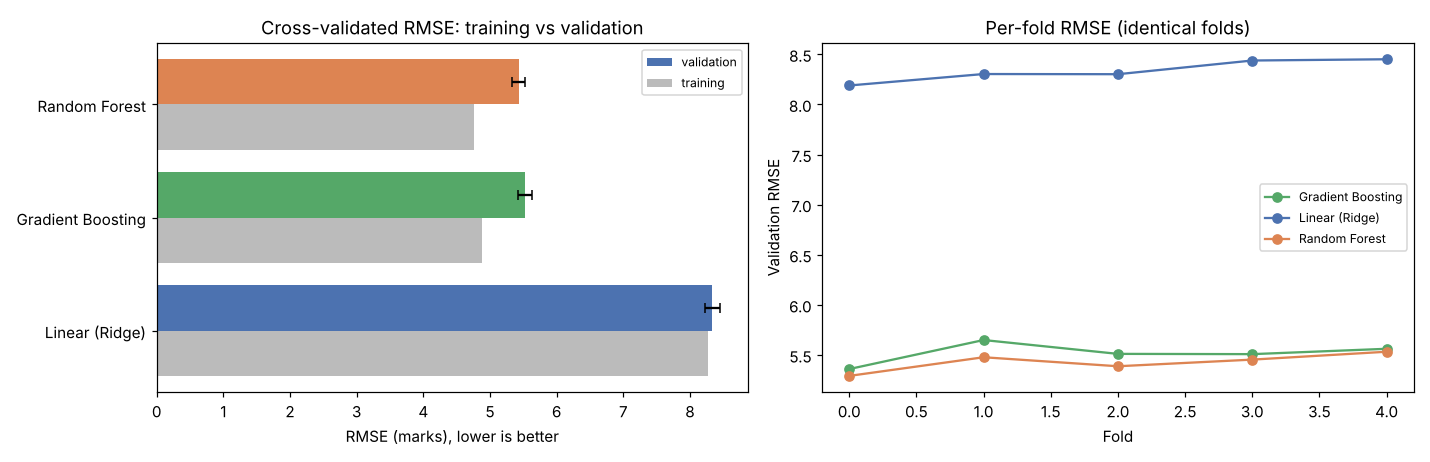

,model_a,model_b,mean_rmse_diff_a_minus_b,a_better_folds,paired_t_p_value
0,gradient_boosting,linear_regression,-2.8177,5/5,0.0000
1,gradient_boosting,random_forest,0.0895,0/5,0.0252
2,linear_regression,random_forest,2.9072,0/5,0.0000


In [19]:
display(Image(RUN / "plots" / "cv_comparison.png"))
metric("cv_paired_tests").round(4)

### Why is the linear model so far behind, even with splines?

Two possible reasons: curved (non-linear) effects or **interactions** between features. Splines already let the
linear model bend, so the test below separates the two. A boosted model limited to **depth-1 trees** is additive: it
can learn any step or curve per feature, but no interactions. Deeper trees allow interactions.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from src.features import build_preprocessor
feats = cfg["features"]["categorical"] + cfg["features"]["numeric"]
X_tr, _, y_tr, _ = train_test_split(df[feats], df.final_test, test_size=cfg["data"]["test_size"],
                                    random_state=cfg["seed"], stratify=df.final_test < WEAK)
rows = []
for depth in [1, 2, 3, None]:
    m = Pipeline([("prep", build_preprocessor(cfg["features"]["categorical"], cfg["features"]["numeric"], False)),
                  ("model", HistGradientBoostingRegressor(max_depth=depth, max_iter=600, learning_rate=0.05,
                                                          random_state=cfg["seed"]))])
    rmse = -cross_val_score(m, X_tr, y_tr, cv=KFold(5, shuffle=True, random_state=43),
                            scoring="neg_root_mean_squared_error").mean()
    rows.append({"max tree depth": "unlimited" if depth is None else depth,
                 "interactions allowed": "none (additive)" if depth == 1 else "yes", "CV RMSE": round(rmse, 3)})
display(pd.DataFrame(rows))
df.groupby(["number_of_siblings", pd.cut(df.class_size, [0, 20, 25, 70])], observed=True).final_test.mean().unstack().round(1)

,max tree depth,interactions allowed,CV RMSE
0,1,none (additive),8.116
1,2,yes,6.763
2,3,yes,6.065
3,unlimited,yes,5.514


class_size,"(0, 20]","(20, 25]","(25, 70]"
number_of_siblings,,,
0,77.5,77.6,69.0
1,80.5,64.0,55.3
2,68.6,58.6,NaN


**Verified: interactions explain the gap.** The additive boosted model reaches only ≈ 8.1 RMSE, the same as the
spline Ridge (≈ 8.3), even though it can fit any step shape. Allowing interactions (depth 2 → unlimited) drops RMSE
to ≈ 5.5. Example: an only child scores about the same in a class of 21–25 as in a smaller class (≈ 78), but a
student with one sibling drops from 80 to 64. The effect of one feature depends on another, which a linear model
cannot represent without hand-built interaction terms.

### Selection and weak-student cut-off (training out-of-fold predictions only)

Selection rule: Lowest mean CV RMSE; models within 1% are tied and the tie is broken by out-of-fold F2 for flagging weak students


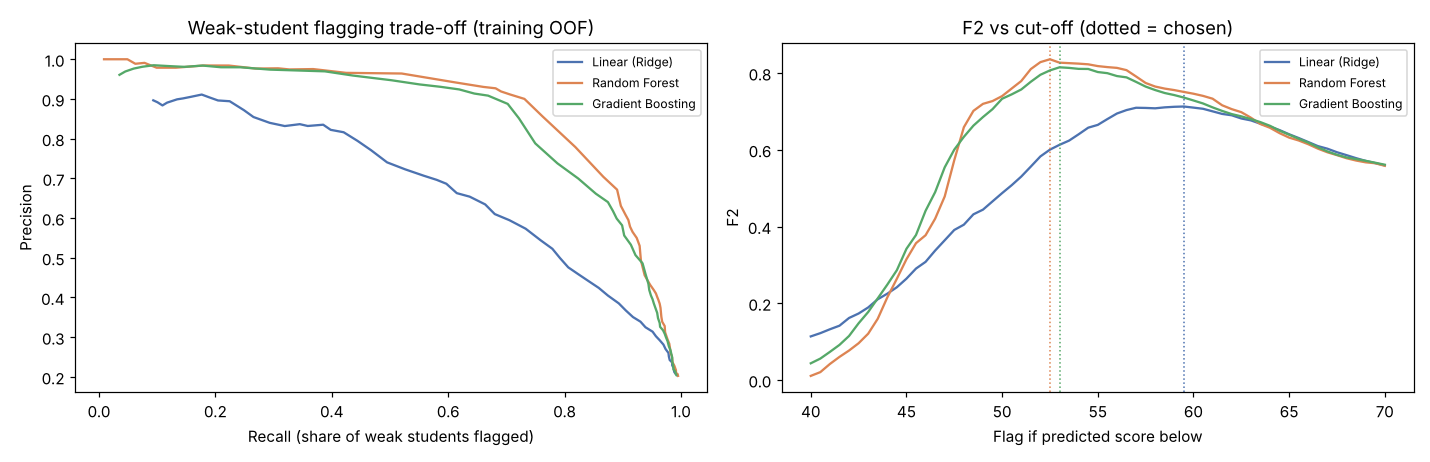

,cv_rmse,cutoff,oof_f2,oof_recall,oof_precision,tied_for_best,selected
model,,,,,,,
random_forest,5.429,52.5,0.836,0.890,0.672,True,True
gradient_boosting,5.519,53.0,0.815,0.874,0.640,False,False
linear_regression,8.336,59.5,0.713,0.859,0.424,False,False


In [21]:
print("Selection rule:", card["selection_rule"])
display(Image(RUN / "plots" / "weak_student_tradeoff.png"))
metric("selection", index_col=0).round(3)

### Held-out test set

In [22]:
test = metric("test_results", index_col=0)
test[["rmse", "mae", "r2", "within_5_marks", "rmse_weak_students", "bias_weak_students", "weak_cutoff",
      "weak_recall", "weak_precision", "weak_f2", "weak_pr_auc", "weak_caught", "weak_missed", "weak_false_alarms",
      "predict_ms_per_1000"]].astype(float).round(3)

,rmse,mae,r2,within_5_marks,rmse_weak_students,bias_weak_students,weak_cutoff,weak_recall,weak_precision,weak_f2,weak_pr_auc,weak_caught,weak_missed,weak_false_alarms,predict_ms_per_1000
linear_regression,8.591,6.765,0.633,0.463,10.826,6.656,59.5,0.828,0.409,0.687,0.670,288.0,60.0,416.0,4.233
random_forest,5.495,3.900,0.850,0.737,5.962,2.908,52.5,0.911,0.692,0.857,0.905,317.0,31.0,141.0,23.446
gradient_boosting,5.575,4.003,0.846,0.725,6.288,2.699,53.0,0.868,0.668,0.819,0.885,302.0,46.0,150.0,17.038


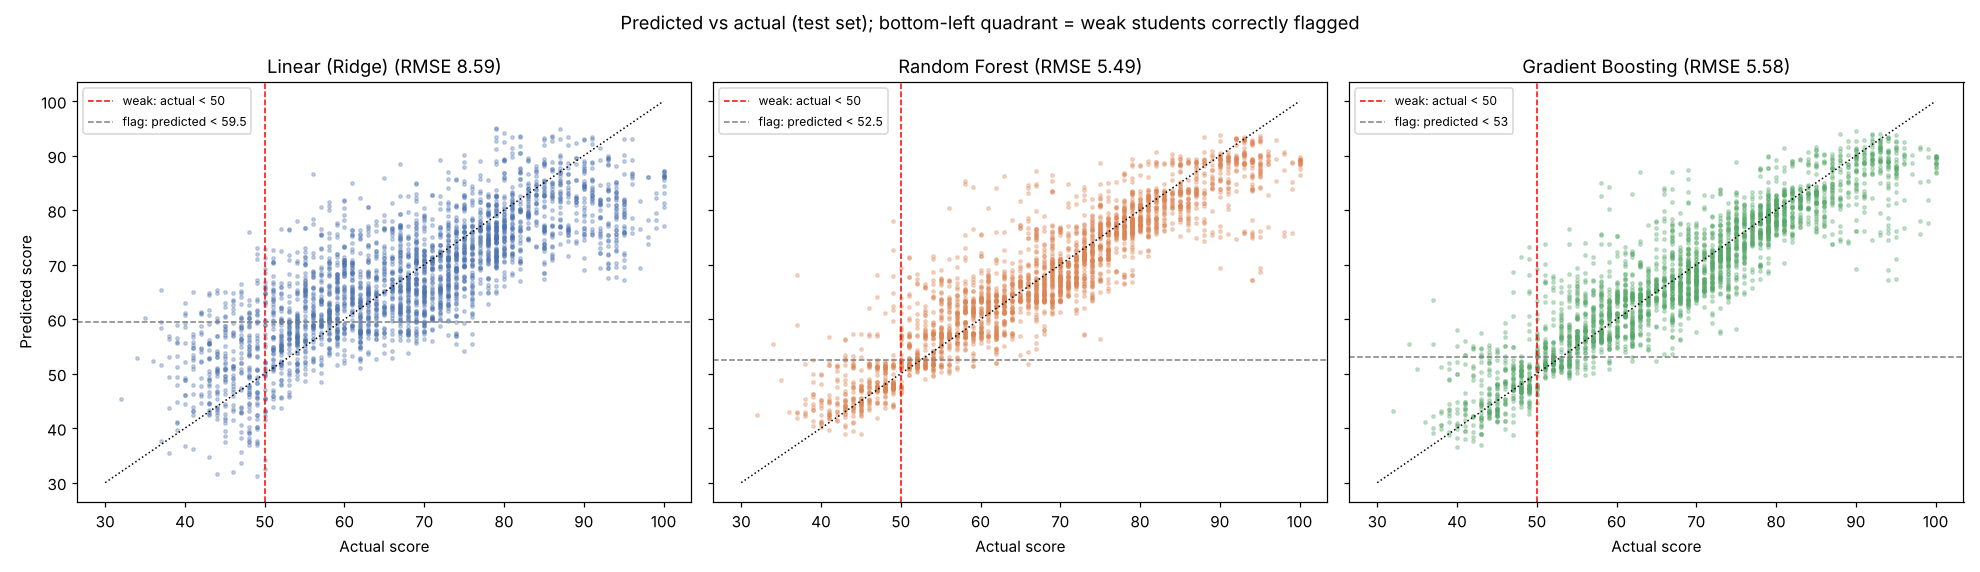

In [23]:
display(Image(RUN / "plots" / "predicted_vs_actual.png"))

In [24]:
metric("test_bootstrap_comparisons").round(4)

,model_a,model_b,rmse_diff_a_minus_b,rmse_ci_low,rmse_ci_high,weak_recall_diff_a_minus_b,recall_ci_low,recall_ci_high
0,linear_regression,random_forest,3.0986,2.8921,3.3005,-0.0833,-0.1206,-0.0466
1,linear_regression,gradient_boosting,3.0186,2.8034,3.2185,-0.0410,-0.0814,-0.0030
2,random_forest,gradient_boosting,-0.0800,-0.1579,-0.0003,0.0423,0.0186,0.0684


In [25]:
metric("error_by_score_band", index_col=0).round(2)

,n,linear_regression_mae,linear_regression_bias,random_forest_mae,random_forest_bias,gradient_boosting_mae,gradient_boosting_bias
<45,139,10.31,9.76,5.04,4.63,5.33,4.32
45-49,209,8.05,4.59,3.11,1.76,3.56,1.62
50-59,575,6.83,5.45,4.06,2.82,4.02,2.63
60-69,653,5.62,1.19,3.82,0.45,3.97,0.48
70-79,726,5.46,-3.04,3.40,-1.41,3.45,-1.23
80+,610,8.23,-6.86,4.44,-3.49,4.53,-3.39


## 7. What drives the predictions

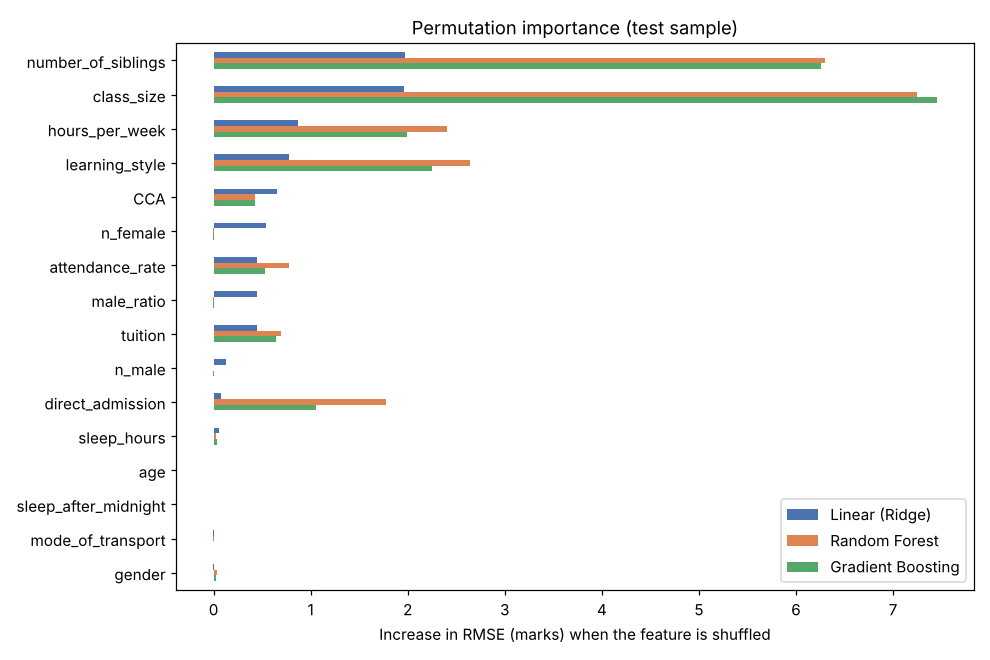

,linear_regression,random_forest,gradient_boosting
number_of_siblings,1.976,6.300,6.260
class_size,1.960,7.245,7.455
hours_per_week,0.874,2.404,1.991
learning_style,0.780,2.637,2.245
CCA,0.658,0.429,0.428
n_female,0.544,-0.003,-0.010
attendance_rate,0.452,0.779,0.534
male_ratio,0.447,-0.005,-0.008
tuition,0.443,0.697,0.639
n_male,0.133,0.000,-0.003


In [26]:
display(Image(RUN / "plots" / "permutation_importance.png"))
metric("permutation_importance", index_col=0).round(3)

## 8. Final comparison and recommendation

In [27]:
final = pd.DataFrame({
    "CV RMSE": cv["rmse_mean"], "CV RMSE sd": cv["rmse_std"], "Train-val gap": cv["overfit_gap"],
    "Test RMSE": test["rmse"], "Test MAE": test["mae"], "Test R²": test["r2"],
    "Within 5 marks": test["within_5_marks"], "RMSE on weak students": test["rmse_weak_students"],
    "Weak recall": test["weak_recall"], "Weak precision": test["weak_precision"], "Weak F2": test["weak_f2"],
    "Fit s": cv["fit_seconds_mean"],
}).astype(float).rename(index=NAMES)
final.sort_values("CV RMSE").round(3)

,CV RMSE,CV RMSE sd,Train-val gap,Test RMSE,Test MAE,Test R²,Within 5 marks,RMSE on weak students,Weak recall,Weak precision,Weak F2,Fit s
Random Forest,5.429,0.093,0.663,5.495,3.900,0.850,0.737,5.962,0.911,0.692,0.857,1.385
Gradient Boosting,5.519,0.105,0.634,5.575,4.003,0.846,0.725,6.288,0.868,0.668,0.819,1.199
Linear (Ridge),8.336,0.109,0.059,8.591,6.765,0.633,0.463,10.826,0.828,0.409,0.687,0.063


### Interpretation

**1. The linear model is clearly unsuitable**, even with splines.
- Accuracy: CV RMSE 8.34 vs 5.43–5.52 for the tree models; R² 0.63 vs 0.85. It loses every CV fold
  (p < 0.001), and its test RMSE is about 3.1 marks worse (95% CI 2.9–3.3).
- Weak students: to catch most of them it needs a high cut-off (59.5), producing **416 false alarms** against 141 for
  the Random Forest, and it still misses 60 weak students against 31.
- Why: it **under-fits** (training and validation error are almost equal at about 8.3) because the data contains
  strong **interactions** (verified above), e.g. siblings × class size.

**2. Random Forest beats Gradient Boosting by a small but consistent margin.**
- Accuracy: CV RMSE 5.43 vs 5.52, better on all 5 folds (p = 0.025); test RMSE 5.49 vs 5.58 (95% CI of the
  difference excludes zero, barely). In marks, the gap is small (0.08–0.09).
- **Weak students, which is what the school cares about:** recall **91% vs 87%** at a similar precision
  (69% vs 67%). On the test set it catches **317 of 348** weak students against 302, i.e. **15 more students
  identified**, with 9 fewer false alarms. The recall advantage is significant (95% CI +1.9 to +6.8 points).
- It is also the more accurate model for the weakest students (RMSE 5.96 vs 6.29 for actual scores < 50).
- Neither tree model over-fits badly: training error is only ~0.65 marks below validation error for both.

**3. What the predictions can and cannot do**
- Typical error is about ±4 marks (MAE 3.9); 74% of predictions are within 5 marks.
- All models over-predict the weakest students (by about +4.6 marks below 45) and under-predict the strongest, a
  normal regression-to-the-mean effect. This is why the chosen flag cut-off (52.5) sits **above** the weak
  threshold of 50: it compensates, so that 91% of weak students are still flagged.
- The strongest predictors are class size, number of siblings, learning style, weekly study hours and direct
  admission. Gender, transport, age and sleep hours contribute nothing once the other features are known.

### Recommendation

**Use the Random Forest** (selected automatically by the pre-declared rule: lowest CV RMSE, not within 1% of any
other model). Flag students whose predicted score is **below 52.5**. On unseen students this identifies about 9 in
10 weak students, and about 7 in 10 flagged students are genuinely weak. That is a reasonable trade-off when the
"cost" of a false alarm is extra support for a student who would have passed anyway.

Gradient Boosting is a close second (and a little faster to score) and would be an acceptable alternative; the
linear model should only be used if a fully transparent formula is required, at a large cost in accuracy.

**How the school can use it**
- Run `python main.py predict` on the new cohort at the start of the year; the output is sorted from the lowest
  predicted score.
- Prioritise flagged students for remedial classes and check the actionable drivers: **attendance below 80%**,
  **sleeping after midnight** and **very low study hours**.
- Treat predictions as a screening tool, not a label: review flagged students with teachers, and retrain each year
  with the new results (`python main.py train`).

## 9. Using the selected model

In [28]:
print(json.dumps({k: card[k] for k in ["model_name", "weak_student_definition", "flag_cutoff", "cutoff_basis",
                                        "hyperparameters", "cv", "test"]}, indent=2))

{
  "model_name": "random_forest",
  "weak_student_definition": "actual score < 50",
  "flag_cutoff": 52.5,
  "cutoff_basis": "Maximises F2 (recall weighted 2x) on out-of-fold training predictions",
  "hyperparameters": {
    "max_depth": 10,
    "max_features": 0.6024,
    "min_samples_leaf": 1,
    "n_estimators": 258
  },
  "cv": {
    "rmse_mean": 5.429241917352124,
    "rmse_std": 0.09258543169630373,
    "r2_mean": 0.8478500907020832
  },
  "test": {
    "rmse": 5.4945868830811175,
    "mae": 3.899652099204199,
    "r2": 0.8499740411390723,
    "within_5_marks": 0.7372939560439561,
    "rmse_weak_students": 5.962381476000885,
    "weak_recall": 0.9109195402298851,
    "weak_precision": 0.6921397379912664,
    "weak_f2": 0.8567567567567568
  }
}


```bash
python main.py predict --input students.csv --output scored.csv
```

The input passes the same schema validation and cleaning as the training data. The output lists every student with a
predicted score and a `flag_for_support` column, **sorted from the lowest predicted score**, so the school can start
with the students most at risk.